# Отчет: Fraud Detection (IEEE-CIS)

## 0. Описание задачи
**Задача:** Бинарная классификация транзакций для выявления мошенничества (Fraud Detection).
**Данные:** Датасет IEEE-CIS Fraud Detection (Kaggle). 
**Цель:** Предсказать целевую переменную isFraud (1 — мошенничество, 0 — легитимная транзакция) на основе признаков транзакции (сумма, данные карты, устройство, email и т.д.).
**Особенность:** Экстремальный дисбаланс классов (мошенничеств всего ~3.5%), наличие большого количества пропусков и анонимизированных признаков. В исходном test датасета нет ответов, поэтому все метрики считаются на валидационной выборке, выделенной из исходного train.

## 1. Чтение данных и разбиение
Исходный датасет состоит из ~590 000 строк и 400+ признаков. Из-за большого объема данные были раздроблены на 60 parquet-файлов для экономии оперативной памяти. 

Мы разбили данные на две части (Train 80% / Val 20%), используя **стратифицированное разбиение** (stratify=y). Это гарантирует, что доля мошенничеств (3.5%) сохранится и в обучающей, и в валидационной выборках. Мы не трогали исходный test, так как в нем нет правильных ответов.

## 3. Визуализация и основные характеристики
В ходе разведочного анализа были выявлены следующие особенности:

1. **Экстремальный дисбаланс классов.** Мошенничества составляют всего ~3.5% от всех транзакций. Это значит, что метрика *Accuracy* здесь бесполезна: модель, которая всегда предсказывает «0» (легитимно), даст 96.5% точности, но не поймает ни одного мошенника, поэтому использовали ROC-AUC.
2. **Пропуски.** В среднем по датасету ~40% пропущенных значений. В некоторых признаках (например, id_24, dist2) пропуски достигают 90%.
3. **Корреляции.** Матрица корреляций Спирмена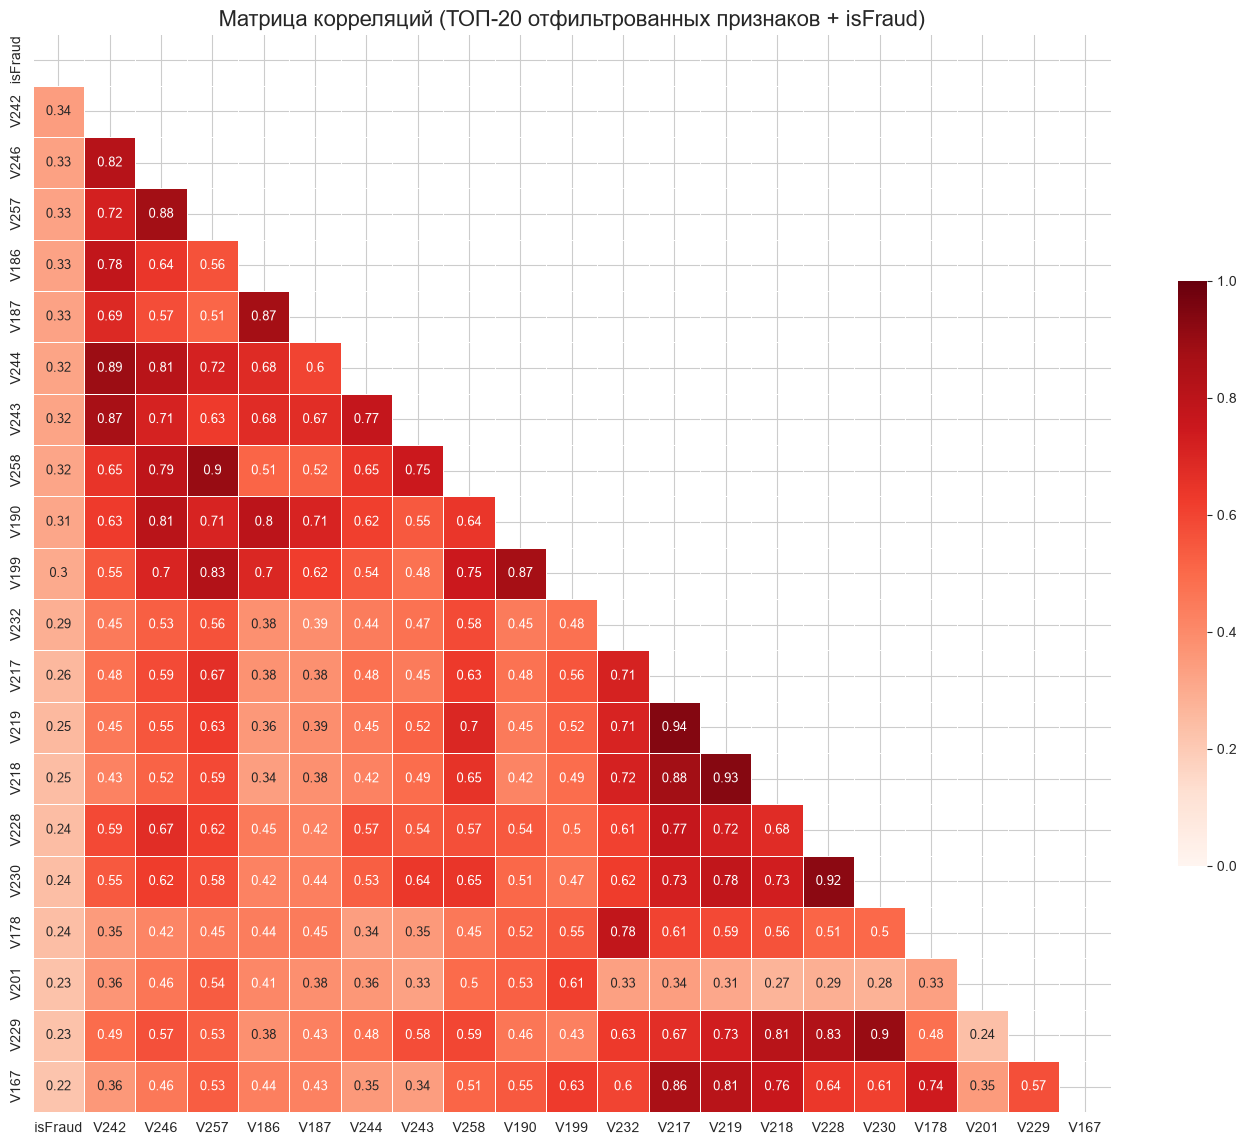

## 4. Обработка выбросов
Мы применили классический метод **IQR (ящик с усами Тьюки)** для признака TransactionAmt (сумма транзакции). 
*   Границы были определены как Q1 - 1.5 * IQR и Q3 + 1.5 * IQR. 
*   Всё, что выходило за эти пределы, удалялось **только из обучающей выборки (train)**.
*   В валидации (val) выбросы оставлены нетронутыми, чтобы имитировать реальные «грязные» данные, с которыми модель столкнется в продакшене.
*   **Результат:** удалено ~11.26% строк. Баланс классов при этом сохранился (мошенничеств осталось ~3.30%).

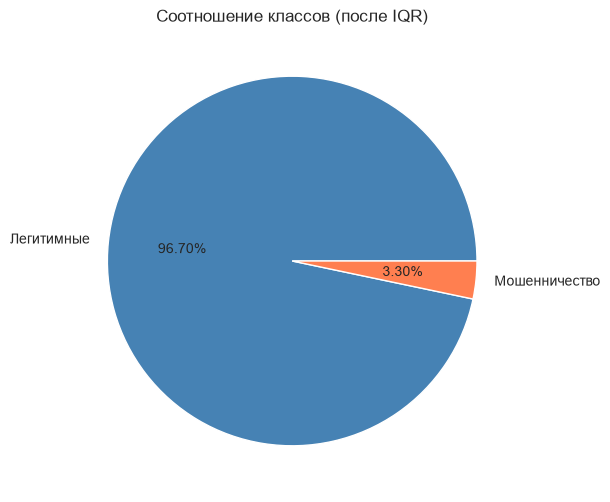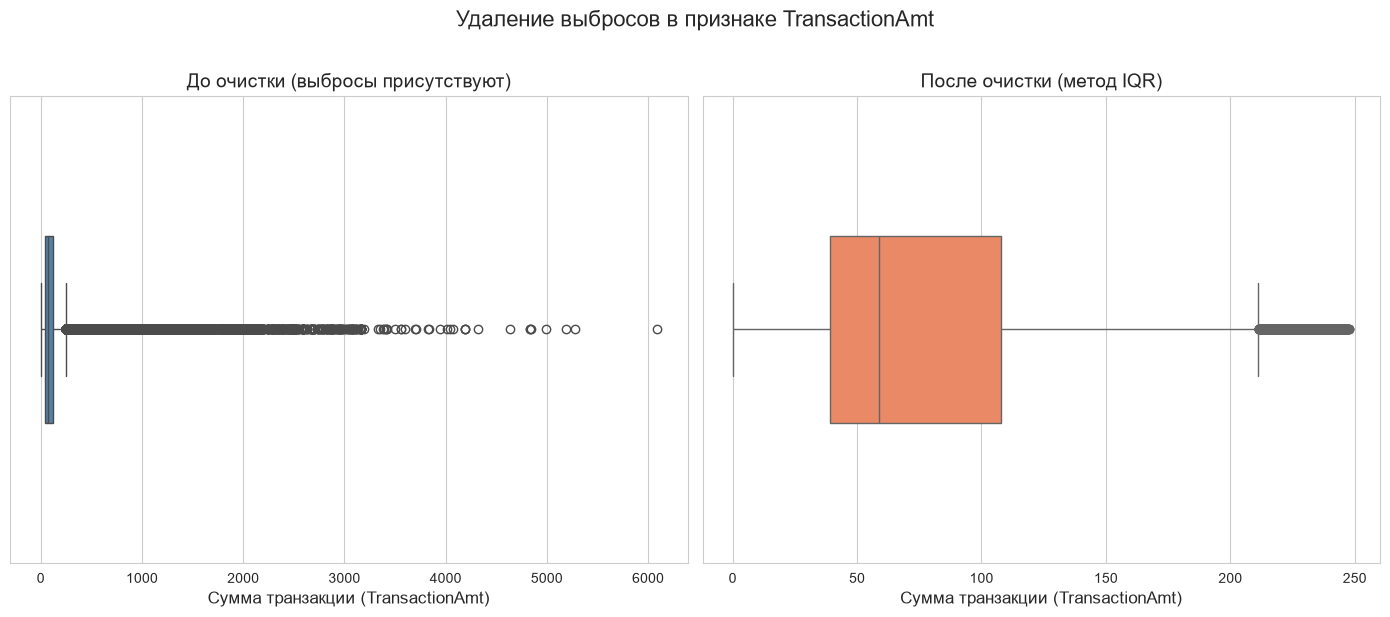

## 5. Обработка пропущенных значений
*   В **числовых** признаках пропуски заполнены медианой (рассчитанной строго по train, чтобы избежать утечки данных / data leakage).
*   В **категориальных** признаках пропуски не заполнялись, а при кодировании через One-Hot использовался параметр dummy_na=True. Это превращает NaN в отдельную категорию (например, DeviceType_nan), что сохраняет информацию о том, что данных не было.

## 6. Обработка категориальных признаков
У нас было 37 категориальных признаков (например, ProductCD, DeviceInfo, P_emaildomain). 
*   Для **LightGBM** мы просто конвертировали их в тип category, так как деревья решений умеют с ними работать нативно.
*   Для **Logistic Regression** и **Random Forest** применили One-Hot Encoding с drop_first=True для избежания мультиколлинеарности (dummy variable trap).

## 7. Нормализация
*   Для **Logistic Regression** нормализация обязательна (использовали StandardScaler)
*   Для **LightGBM** и **Random Forest** нормализация **не нужна**

## 8. Выбор классификаторов
Мы обучили три модели:
1.  **LightGBM (Градиентный бустинг):** Стандарт для табличных данных. Нативно работает с пропусками и категориями, быстрый и точный.
2.  **Logistic Regression:** Линейная базовая модель. Быстрая, интерпретируемая.
3.  **Random Forest:** Классический бэггинг. Устойчив к переобучению и шуму.

## 11. Борьба с несбалансированностью классов
Мы использовали несколько подходов одновременно:
*   **Веса классов:** class_weight='balanced' для LogReg и RF, и scale_pos_weight (коэффициент ~27.5) для LightGBM. Это говорит модели, что ошибка на мошеннике «стоит» в 27 раз дороже, чем на честном клиенте.

## 12. Исключение коррелированных переменных
С помощью корреляции Спирмена мы удалили 136 мультиколлинеарных признаков (коэффициент > 0.95). 
Это уменьшило размерность с 378 до 214 числовых признаков. Удаление «дубликатов» снижает риск переобучения, ускоряет обучение и экономит память, не теряя при этом информации (так как один из пары коррелирующих признаков избыточен).

## 13. Общие выводы
В ходе работы был проведен полный цикл подготовки данных (EDA, очистка от выбросов, импутация пропусков, кодирование категорий, отбор признаков). 
Несмотря на экстремальный дисбаланс классов, нам удалось обучить модель (LightGBM), которая показывает высокий ROC-AUC (0.93) и успешно выявляет мошенничества.